# R7 - Análisis de sensibilidad del mapeo binario

**Objetivo.** Estudiar cómo la agrupación de las categorías originales de MMOTU en una etiqueta binaria condiciona la lectura de las predicciones de ConvNeXt-Tiny con la imagen completa (representación A), en B0 (basal) y B2 (Cross Entropy con pesos atenuados, α = 0.5).

**Mapeo operacional (no se modifica).** Las categorías 0-5 son la clase 0 y las categorías 6-7 son la clase 1. La categoría 6 es el cistoadenoma mucinoso y **no** se describe como malignidad histológica; por eso la clase 1 se llama aquí *positiva operacional*.

**Validation (200 imágenes).** 178 negativas operacionales (categorías 0-5), 15 de categoría 6 y 7 de categoría 7.

**Qué hace.**

1. Verifica la correspondencia por `image_id` entre las predicciones y la partición experimental, y la distribución por categoría.
2. Cuenta, por configuración y semilla, cuántas imágenes de categoría 6 y de categoría 7 se clasifican como positivas con el umbral original de 0.5.
3. Calcula, como **análisis secundario**, las métricas de la distinción categoría 7 frente a categorías 0-5, excluyendo la categoría 6. Es un subconjunto distinto (185 imágenes) del de la tarea principal (200): sus métricas no son comparables con las de B0-B3 y no las sustituyen.
4. Compara B0 y B2 de forma descriptiva.

**Qué no hace.** No reentrena (los modelos se entrenaron con el mapeo operacional), no usa test, no modifica el mapeo, los CSV ni los experimentos B0-B3, y no estima validez clínica.

## 1. Configuración

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import average_precision_score, roc_auc_score


def locate_project_root() -> Path:
    current_dir = Path.cwd().resolve()

    for candidate in [current_dir, *current_dir.parents]:
        if (candidate / "src").exists() and (candidate / "data").exists():
            return candidate

    raise FileNotFoundError("No se pudo localizar la raíz del proyecto.")


PROJECT_ROOT = locate_project_root()

SEEDS = [42, 43, 44]
THRESHOLD = 0.5  # umbral original: probabilidad >= 0.5 es positiva (igual que train.py)
NEGATIVE_CLASSES = [0, 1, 2, 3, 4, 5]
EXPECTED_VALIDATION = {"negativas (0-5)": 178, 6: 15, 7: 7}

CLASSIFICATION_DIR = PROJECT_ROOT / "results" / "classification"
R7_DIR = CLASSIFICATION_DIR / "r7_optimizacion"
CONFIG_DIRS = {
    "B0": CLASSIFICATION_DIR / "r4_benchmark" / "convnext_tiny" / "A",
    "B2": R7_DIR / "class_weights",
}
CONFIGS = list(CONFIG_DIRS)
SPLIT_CSV = PROJECT_ROOT / "configs" / "splits" / "mmotu_experimental_split.csv"
OUT_DIR = R7_DIR / "analisis_mapeo_binario"  # salidas de este notebook; no toca B0-B3

## 2. Integridad

Se recupera `original_class` desde la partición experimental mediante `image_id` (sin depender del orden de filas) y se comprueba, para las seis corridas (B0 y B2 × 3 semillas): conjunto de `image_id` idéntico al de validation, `image_id` únicos, `y_true` igual a `binary_label` de la partición, y mapeo operacional consistente (`binary_label = 1` si y solo si la categoría es 6 o 7).

In [2]:
split = pd.read_csv(SPLIT_CSV)
assert split["image_id"].is_unique, "image_id repetidos en la partición"
assert (split["binary_label"] == split["original_class"].isin([6, 7]).astype(int)).all(), "El mapeo operacional no es 6-7 = 1"

validation = split[split["experimental_split"] == "validation"].set_index("image_id").sort_index()
counts = validation["original_class"].value_counts().sort_index()
observed = {"negativas (0-5)": int(counts[NEGATIVE_CLASSES].sum()), 6: int(counts[6]), 7: int(counts[7])}
assert observed == EXPECTED_VALIDATION, observed
assert len(validation) == 200

display(
    pd.DataFrame(
        {"imágenes en validation": counts, "binary_label": validation.groupby("original_class")["binary_label"].first()},
    ).rename_axis("original_class")
)

REQUIRED_COLUMNS = ["image_id", "y_true", "probability_malignant"]


def read_predictions(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path)
    missing_columns = set(REQUIRED_COLUMNS) - set(df.columns)
    assert not missing_columns, f"{path}: faltan columnas {sorted(missing_columns)}"
    assert not df[REQUIRED_COLUMNS].isna().any().any(), f"{path}: valores faltantes"
    assert df["image_id"].is_unique, f"{path}: image_id repetidos"
    assert df["probability_malignant"].between(0, 1).all(), f"{path}: probabilidades fuera de [0, 1]"
    return df.set_index("image_id").sort_index()


PRED = {
    (config, seed): read_predictions(directory / f"seed_{seed}" / "val_predictions_best_auc.csv")
    for config, directory in CONFIG_DIRS.items()
    for seed in SEEDS
}

rows = []
for (config, seed), df in PRED.items():
    same_ids = df.index.equals(validation.index)
    same_labels = same_ids and np.array_equal(df["y_true"].to_numpy(), validation["binary_label"].to_numpy())
    rows.append({"config": config, "seed": seed, "n": len(df), "mismo conjunto de image_id": same_ids, "y_true = binary_label": same_labels})
integrity = pd.DataFrame(rows)
display(integrity)
assert integrity["mismo conjunto de image_id"].all() and integrity["y_true = binary_label"].all()

# Tabla común alineada por image_id: una fila por imagen, una columna por (config, semilla)
IMAGES = validation[["original_class", "binary_label"]].copy()
for (config, seed), df in PRED.items():
    IMAGES[f"{config}_{seed}"] = df["probability_malignant"]
print("Integridad correcta: 6 archivos, 200 imágenes con la misma correspondencia image_id / categoría / etiqueta.")

,imágenes en validation,binary_label
original_class,,
0,48,0
1,30,0
2,50,0
3,11,0
4,8,0
5,31,0
6,15,1
7,7,1


,config,seed,n,mismo conjunto de image_id,y_true = binary_label
0,B0,42,200,True,True
1,B0,43,200,True,True
2,B0,44,200,True,True
3,B2,42,200,True,True
4,B2,43,200,True,True
5,B2,44,200,True,True


Integridad correcta: 6 archivos, 200 imágenes con la misma correspondencia image_id / categoría / etiqueta.


## 3. Clasificación por categoría original (umbral 0.5)

Para cada configuración y semilla, cuántas imágenes de cada categoría se clasifican como positivas. Las categorías 0-5 son negativas operacionales (una predicción positiva es un falso positivo); las categorías 6 y 7 son positivas operacionales (una predicción positiva es un verdadero positivo).

In [3]:
category_rows = []
for config in CONFIGS:
    for seed in SEEDS:
        prob = IMAGES[f"{config}_{seed}"]
        for category, group in prob.groupby(IMAGES["original_class"]):
            n_positive = int((group >= THRESHOLD).sum())
            category_rows.append(
                {
                    "config": config,
                    "seed": seed,
                    "original_class": category,
                    "etiqueta_operacional": int(category in (6, 7)),
                    "n": len(group),
                    "clasificadas_positivas": n_positive,
                    "clasificadas_negativas": len(group) - n_positive,
                    "fraccion_positiva": n_positive / len(group),
                    "prob_mediana": group.median(),
                }
            )
by_category = pd.DataFrame(category_rows)

focus = by_category[by_category["original_class"].isin([6, 7])].pivot(index=["config", "seed"], columns="original_class", values=["clasificadas_positivas", "clasificadas_negativas"])
focus.columns = [f"cat {category}: {name.replace('clasificadas_', '')}" for name, category in focus.columns]
display(focus[["cat 6: positivas", "cat 6: negativas", "cat 7: positivas", "cat 7: negativas"]])

negatives = by_category[by_category["original_class"].isin(NEGATIVE_CLASSES)].groupby(["config", "seed"])["clasificadas_positivas"].sum().rename("falsos positivos (178 negativas)")
display(negatives.to_frame())

OUT_DIR.mkdir(parents=True, exist_ok=True)
by_category.round(4).to_csv(OUT_DIR / "clasificacion_por_categoria.csv", index=False)

cat 6: positivas  cat 6: negativas  cat 7: positivas  \
config seed                                                         
B0     42                  12                 3                 5   
       43                   4                11                 3   
       44                   3                12                 3   
B2     42                   9                 6                 3   
       43                   7                 8                 4   
       44                   4                11                 3   

             cat 7: negativas  
config seed                    
B0     42                   2  
       43                   4  
       44                   4  
B2     42                   4  
       43                   3  
       44                   4

falsos positivos (178 negativas)
config seed                                  
B0     42                                  40
       43                                   4
       44                                   1
B2     42                                  12
       43                                   5
       44                                   2

## 4. Análisis secundario: categoría 7 frente a categorías 0-5

Se excluye la categoría 6 y se evalúa si las predicciones, entrenadas con el mapeo operacional, separan la categoría 7 (7 imágenes) de las categorías 0-5 (178 imágenes). **Es un subconjunto distinto del de la tarea principal** (185 frente a 200 imágenes, 7 frente a 22 positivas): sus métricas no son comparables con las de B0-B3. Las métricas de la tarea principal se recalculan aquí solo como referencia y se contrastan con `validation_metrics.json`.

Como las negativas son las mismas, la especificidad coincide con la de la tarea principal; la sensibilidad es la de la categoría 7 únicamente. El AP de un clasificador sin información es la prevalencia de positivas (22/200 = 0.110 en la tarea principal y 7/185 = 0.038 en el análisis secundario).

In [4]:
def binary_metrics(y_true, prob):
    y_true = np.asarray(y_true)
    pred = np.asarray(prob) >= THRESHOLD
    n_pos, n_neg = int((y_true == 1).sum()), int((y_true == 0).sum())
    both_classes = n_pos > 0 and n_neg > 0  # AP y ROC-AUC solo están definidos con ambas clases
    return {
        "n": len(y_true),
        "n_positivas": n_pos,
        "ap": average_precision_score(y_true, prob) if both_classes else np.nan,
        "roc_auc": roc_auc_score(y_true, prob) if both_classes else np.nan,
        "sensibilidad": pred[y_true == 1].mean() if n_pos else np.nan,
        "especificidad": (~pred[y_true == 0]).mean() if n_neg else np.nan,
        "prevalencia (AP base)": n_pos / len(y_true),
    }


TASKS = {
    "principal: 0-5 vs 6-7": IMAGES["original_class"] >= 0,
    "secundaria: 0-5 vs 7": IMAGES["original_class"] != 6,
}

metric_rows = []
for config in CONFIGS:
    for seed in SEEDS:
        for task, mask in TASKS.items():
            subset = IMAGES[mask]
            y_task = (subset["original_class"] >= 7).astype(int) if task.startswith("secundaria") else subset["binary_label"]
            metric_rows.append({"config": config, "seed": seed, "tarea": task, **binary_metrics(y_task, subset[f"{config}_{seed}"])})
metrics = pd.DataFrame(metric_rows)

# Contraste de la tarea principal con las métricas guardadas
for _, row in metrics[metrics["tarea"].str.startswith("principal")].iterrows():
    saved = json.loads((CONFIG_DIRS[row["config"]] / f"seed_{row['seed']}" / "validation_metrics.json").read_text(encoding="utf-8"))
    for mine, key in [("ap", "average_precision"), ("roc_auc", "roc_auc"), ("sensibilidad", "recall_malignant"), ("especificidad", "specificity")]:
        assert abs(row[mine] - saved[key]) < 1e-8, (row["config"], row["seed"], mine, row[mine], saved[key])
print("Tarea principal: AP, ROC-AUC, sensibilidad y especificidad recalculados = validation_metrics.json en las 6 corridas.")

metrics.round(4).to_csv(OUT_DIR / "metricas_por_tarea.csv", index=False)
display(metrics.drop(columns=["n_positivas"]).round(4))

Tarea principal: AP, ROC-AUC, sensibilidad y especificidad recalculados = validation_metrics.json en las 6 corridas.


,config,seed,tarea,n,ap,roc_auc,sensibilidad,especificidad,prevalencia (AP base)
0,B0,42,principal: 0-5 vs 6-7,200,0.5898,0.8853,0.7727,0.7753,0.1100
1,B0,42,secundaria: 0-5 vs 7,185,0.5317,0.9021,0.7143,0.7753,0.0378
2,B0,43,principal: 0-5 vs 6-7,200,0.5295,0.8292,0.3182,0.9775,0.1100
3,B0,43,secundaria: 0-5 vs 7,185,0.5147,0.8058,0.4286,0.9775,0.0378
4,B0,44,principal: 0-5 vs 6-7,200,0.5046,0.8156,0.2727,0.9944,0.1100
5,B0,44,secundaria: 0-5 vs 7,185,0.4973,0.7721,0.4286,0.9944,0.0378
6,B2,42,principal: 0-5 vs 6-7,200,0.6050,0.8639,0.5455,0.9326,0.1100
7,B2,42,secundaria: 0-5 vs 7,185,0.4778,0.7753,0.4286,0.9326,0.0378
8,B2,43,principal: 0-5 vs 6-7,200,0.6501,0.8731,0.5000,0.9719,0.1100
9,B2,43,secundaria: 0-5 vs 7,185,0.5911,0.8483,0.5714,0.9719,0.0378


## 5. Comparación descriptiva B0 y B2 por semilla

Diferencia B2 − B0 con la misma semilla. Con una sola partición, tres semillas y siete imágenes de categoría 7, son observaciones descriptivas; no hay intervalos ni contrastes.

In [5]:
def pick(config, seed, task, column):
    return metrics[(metrics["config"] == config) & (metrics["seed"] == seed) & (metrics["tarea"].str.startswith(task))][column].iloc[0]


def positives_detected(config, seed, category):
    row = by_category[(by_category["config"] == config) & (by_category["seed"] == seed) & (by_category["original_class"] == category)].iloc[0]
    return int(row["clasificadas_positivas"])


comparison_rows = []
for seed in SEEDS:
    row = {"seed": seed}
    for label, task, column in [
        ("ap_principal", "principal", "ap"),
        ("auc_principal", "principal", "roc_auc"),
        ("ap_cat7_vs_0a5", "secundaria", "ap"),
        ("auc_cat7_vs_0a5", "secundaria", "roc_auc"),
    ]:
        row[f"{label}_b0"] = pick("B0", seed, task, column)
        row[f"{label}_b2"] = pick("B2", seed, task, column)
        row[f"{label}_delta"] = row[f"{label}_b2"] - row[f"{label}_b0"]
    for category in (6, 7):
        row[f"cat{category}_positivas_b0"] = positives_detected("B0", seed, category)
        row[f"cat{category}_positivas_b2"] = positives_detected("B2", seed, category)
    row["falsos_positivos_b0"] = int(negatives[("B0", seed)])
    row["falsos_positivos_b2"] = int(negatives[("B2", seed)])
    comparison_rows.append(row)
comparison = pd.DataFrame(comparison_rows)
comparison.round(4).to_csv(OUT_DIR / "comparacion_b0_b2_por_semilla.csv", index=False)

display(comparison[["seed", "ap_principal_b0", "ap_principal_b2", "ap_principal_delta", "ap_cat7_vs_0a5_b0", "ap_cat7_vs_0a5_b2", "ap_cat7_vs_0a5_delta"]].round(4))
display(comparison[["seed", "auc_principal_delta", "auc_cat7_vs_0a5_delta", "cat6_positivas_b0", "cat6_positivas_b2", "cat7_positivas_b0", "cat7_positivas_b2", "falsos_positivos_b0", "falsos_positivos_b2"]].round(4))

mean_row = comparison.drop(columns="seed").mean()
display(mean_row[[c for c in comparison.columns if c.endswith("_delta")]].round(4).to_frame("media de 3 semillas"))

,seed,ap_principal_b0,ap_principal_b2,ap_principal_delta,ap_cat7_vs_0a5_b0,ap_cat7_vs_0a5_b2,ap_cat7_vs_0a5_delta
0,42,0.5898,0.6050,0.0153,0.5317,0.4778,-0.0540
1,43,0.5295,0.6501,0.1205,0.5147,0.5911,0.0764
2,44,0.5046,0.5790,0.0744,0.4973,0.4802,-0.0172


,seed,auc_principal_delta,auc_cat7_vs_0a5_delta,cat6_positivas_b0,cat6_positivas_b2,cat7_positivas_b0,cat7_positivas_b2,falsos_positivos_b0,falsos_positivos_b2
0,42,-0.0215,-0.1268,12,9,5,3,40,12
1,43,0.0439,0.0425,4,7,3,4,4,5
2,44,0.0077,0.0441,3,4,3,3,1,2


,media de 3 semillas
ap_principal_delta,0.0701
auc_principal_delta,0.0100
ap_cat7_vs_0a5_delta,0.0018
auc_cat7_vs_0a5_delta,-0.0134


## 6. Figuras

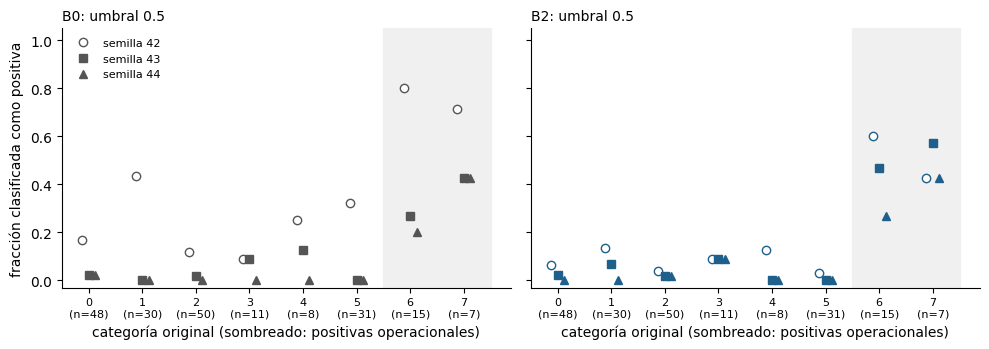

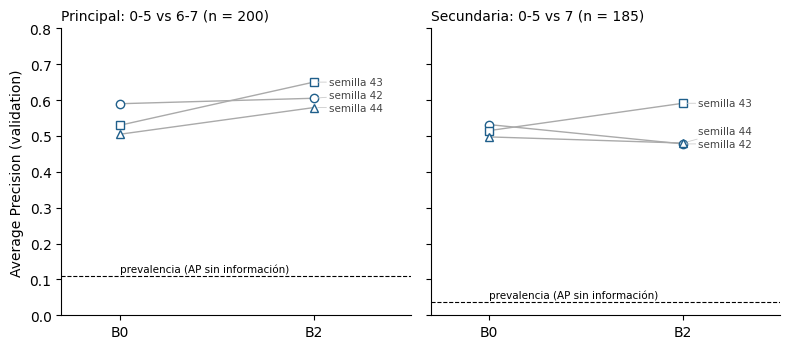

In [6]:
colors = {"B0": "#555555", "B2": "#1f5f8b"}
markers = {42: "o", 43: "s", 44: "^"}
categories = sorted(IMAGES["original_class"].unique())
n_by_category = IMAGES["original_class"].value_counts().sort_index()

# Figura 1: fracción de imágenes clasificadas como positivas, por categoría original
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, config in zip(axes, CONFIGS):
    ax.axvspan(5.5, 7.5, color="#f0f0f0", zorder=0)
    for seed in SEEDS:
        sub = by_category[(by_category["config"] == config) & (by_category["seed"] == seed)].sort_values("original_class")
        ax.plot(sub["original_class"] + (seed - 43) * 0.12, sub["fraccion_positiva"], markers[seed], color=colors[config], ms=6, mfc="white" if seed == 42 else colors[config], label=f"semilla {seed}")
    ax.set_xticks(categories)
    ax.set_xticklabels([f"{c}\n(n={n_by_category[c]})" for c in categories], fontsize=8)
    ax.set_title(f"{config}: umbral {THRESHOLD}", loc="left", fontsize=10)
    ax.set_xlabel("categoría original (sombreado: positivas operacionales)")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].set_ylabel("fracción clasificada como positiva")
axes[0].set_ylim(-0.03, 1.05)
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig(OUT_DIR / "fraccion_positiva_por_categoria.png", dpi=200)
plt.show()

# Figura 2: AP por semilla, B0 -> B2, en la tarea principal y en la secundaria
fig, axes = plt.subplots(1, 2, figsize=(8, 3.6), sharey=True)
for ax, (title, prefix) in zip(axes, [("Principal: 0-5 vs 6-7 (n = 200)", "ap_principal"), ("Secundaria: 0-5 vs 7 (n = 185)", "ap_cat7_vs_0a5")]):
    for _, row in comparison.iterrows():
        ax.plot([0, 1], [row[f"{prefix}_b0"], row[f"{prefix}_b2"]], "-", color="#aaaaaa", lw=1, zorder=1)
        ax.plot([0, 1], [row[f"{prefix}_b0"], row[f"{prefix}_b2"]], markers[int(row["seed"])], color="#1f5f8b", ms=6, mfc="white", zorder=2)
    # etiquetas de semilla a la derecha de B2, separadas para que no se superpongan
    order = comparison.sort_values(f"{prefix}_b2")
    label_y = []
    for value in order[f"{prefix}_b2"]:
        label_y.append(max(value, label_y[-1] + 0.035) if label_y else value)
    for (_, row), y_label in zip(order.iterrows(), label_y):
        ax.annotate(f"semilla {int(row['seed'])}", (1, row[f"{prefix}_b2"]), xytext=(1.08, y_label), textcoords="data", va="center", fontsize=7.5, color="#444444", arrowprops=dict(arrowstyle="-", color="#cccccc", lw=0.6, shrinkA=0, shrinkB=3))
    prevalence = 22 / 200 if prefix == "ap_principal" else 7 / 185
    ax.axhline(prevalence, color="black", lw=0.8, ls="--")
    ax.annotate("prevalencia (AP sin información)", (0.0, prevalence), xytext=(0, 3), textcoords="offset points", fontsize=7.5)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["B0", "B2"])
    ax.set_xlim(-0.3, 1.5)
    ax.set_title(title, loc="left", fontsize=10)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].set_ylabel("Average Precision (validation)")
axes[0].set_ylim(0, 0.8)
fig.tight_layout()
fig.savefig(OUT_DIR / "ap_b0_b2_tarea_principal_vs_secundaria.png", dpi=200)
plt.show()

## 7. Limitaciones

- **Siete imágenes de categoría 7.** Cada una pesa 14 puntos de sensibilidad y mueve mucho el AP; no se calculan intervalos porque no serían informativos con tan pocas positivas. Las cifras del análisis secundario son descriptivas.
- **Sin reentrenamiento bajo el mapeo alternativo.** Los modelos se entrenaron para separar 0-5 de 6-7. Evaluar la categoría 7 frente a 0-5 solo describe cómo se comportan las predicciones existentes sobre otro subconjunto; no es lo que un modelo entrenado para esa tarea habría logrado.
- **Selección sobre este mismo validation.** El checkpoint de cada corrida se eligió por `val_roc_auc` con la tarea principal, y B2 se conservó por esa comparación; no es una evaluación independiente.
- **Posible dependencia entre imágenes.** No hay identificadores de paciente. Si varias imágenes proceden del mismo caso, el número efectivo de observaciones es menor que el de imágenes, especialmente en las categorías con pocas imágenes.
- **Definición operacional de las etiquetas.** Las categorías originales son las del conjunto de datos; su agrupación en 0 y 1 es una convención de este trabajo y la categoría 6 (cistoadenoma mucinoso) no es malignidad histológica. Nada de lo anterior establece validez clínica.
- **Tres semillas.** La variabilidad entre semillas se aprecia en las tablas, pero con tres repeticiones es una estimación imprecisa.

## 8. Conclusión

**Clasificación operacional (0-5 frente a 6-7).** B2 mantiene el AP promedio más alto que B0 (0.611 frente a 0.541; ver el notebook 04 para su incertidumbre). La categoría 6 (cistoadenoma mucinoso, que no es malignidad histológica) representa 15 de las 22 positivas operacionales, pero con estos análisis no puede cuantificarse su contribución individual al incremento de AP. Con el umbral 0.5, B0 clasifica como positivas 19 de 45 imágenes de categoría 6 y 11 de 21 de categoría 7; B2, 20 de 45 y 10 de 21. Estos conteos acumulan las predicciones de tres ejecuciones (una por semilla) sobre las mismas 15 imágenes de categoría 6 y siete de categoría 7 (45 = 3 × 15; 21 = 3 × 7): no son imágenes independientes. En ninguna de las dos configuraciones la categoría 7 se detecta claramente mejor que la 6, y entre semillas la detección varía mucho (categoría 6 en B0: 12, 4 y 3 de 15).

**Análisis alternativo (categoría 7 frente a 0-5, n = 185).** Las predicciones existentes ordenan la categoría 7 muy por encima de la prevalencia (AP entre 0.48 y 0.59 con prevalencia 0.038; ROC-AUC entre 0.77 y 0.90), pero con siete imágenes y modelos no entrenados para esta tarea es una descripción, no una estimación del desempeño de un clasificador de categoría 7. La mejora de B2 en la tarea principal (+0.070 de AP, en las tres semillas) **no se reproduce** aquí: el cambio de AP es +0.002 en promedio y cambia de signo entre semillas (−0.054, +0.076, −0.017). Es coherente con que esa mejora no provenga de la categoría 7, pero con siete imágenes no permite atribuirla a otra categoría.

**Lectura.** Los resultados de B0-B3 siguen siendo los de la tarea operacional y no se modifican. Este análisis acota su interpretación: el desempeño computacional medido corresponde a separar 0-5 de 6-7, no a detectar malignidad histológica, y las cifras del análisis alternativo son exploratorias y no sustentan validez clínica.